In [ ]:
%pip install plotnine
%pip install pandas

In [143]:
import pandas as pd
from plotnine import * #Very similar to R which I'm familair with from Stat 300 level classes.

cars = pd.read_csv("CarsCleaned.csv")

print(cars.describe(include="all"))

                ID Location      Time    Date Day_of_Week Weather    Make  \
count   160.000000      160       160     160         160     160     160   
unique         NaN        4         6       6           4       2      19   
top            NaN  Walmart  10:00 AM  28-Sep      Monday   Sunny  Toyota   
freq           NaN       40        60      40          60     100      24   
mean     80.500000      NaN       NaN     NaN         NaN     NaN     NaN   
std      46.332134      NaN       NaN     NaN         NaN     NaN     NaN   
min       1.000000      NaN       NaN     NaN         NaN     NaN     NaN   
25%      40.750000      NaN       NaN     NaN         NaN     NaN     NaN   
50%      80.500000      NaN       NaN     NaN         NaN     NaN     NaN   
75%     120.250000      NaN       NaN     NaN         NaN     NaN     NaN   
max     160.000000      NaN       NaN     NaN         NaN     NaN     NaN   

        Model   Type  Color Year_Range Modified Mod_Type    Class  Year Sta

In [115]:
cars.info()

<class 'pandas.DataFrame'>
RangeIndex: 160 entries, 0 to 159
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   ID                       160 non-null    int64  
 1   Location                 160 non-null    str    
 2   Time                     160 non-null    str    
 3   Date                     160 non-null    str    
 4   Day_of_Week              160 non-null    str    
 5   Weather                  160 non-null    str    
 6   Make                     160 non-null    str    
 7   Model                    160 non-null    str    
 8   Type                     160 non-null    str    
 9   Color                    160 non-null    str    
 10  Year_Range               160 non-null    str    
 11  Modified                 160 non-null    str    
 12  Mod_Type                 160 non-null    str    
 13  Class                    160 non-null    str    
 14  Year Start               160 non-null

In [116]:
print(cars.nunique())

ID                         160
Location                     4
Time                         6
Date                         6
Day_of_Week                  4
Weather                      2
Make                        19
Model                       60
Type                         7
Color                        9
Year_Range                   5
Modified                     2
Mod_Type                     7
Class                        3
Year Start                   5
Year End                     5
Estimated Year Midpoint      5
Is Modified                  2
dtype: int64


In [117]:
for column in ["Make", "Type", "Color", "Class", "Mod_Type"]:
    print("\n")
    print(cars[column].value_counts())



Make
Toyota           24
Honda            22
Ford             18
Chevrolet        14
Hyundai          13
Kia              11
Nissan            9
Subaru            7
Jeep              6
Lexus             5
Mazda             5
Dodge             5
Acura             5
Volkswagen        4
BMW               4
Chrysler          3
GMC               2
Mercedes-Benz     2
Ram               1
Name: count, dtype: int64


Type
Sedan        69
SUV          58
Pickup        9
Minivan       7
Coupe         7
Hatchback     6
Crossover     4
Name: count, dtype: int64


Color
Black     34
White     33
Silver    28
Gray      26
Blue      17
Red       15
Green      3
Orange     2
Yellow     2
Name: count, dtype: int64


Class
Economy        128
Luxury          20
Performance     12
Name: count, dtype: int64


Mod_Type
Stock       135
Wheels        8
Tint          7
Exhaust       5
Multiple      3
Spoiler       1
LEDs          1
Name: count, dtype: int64


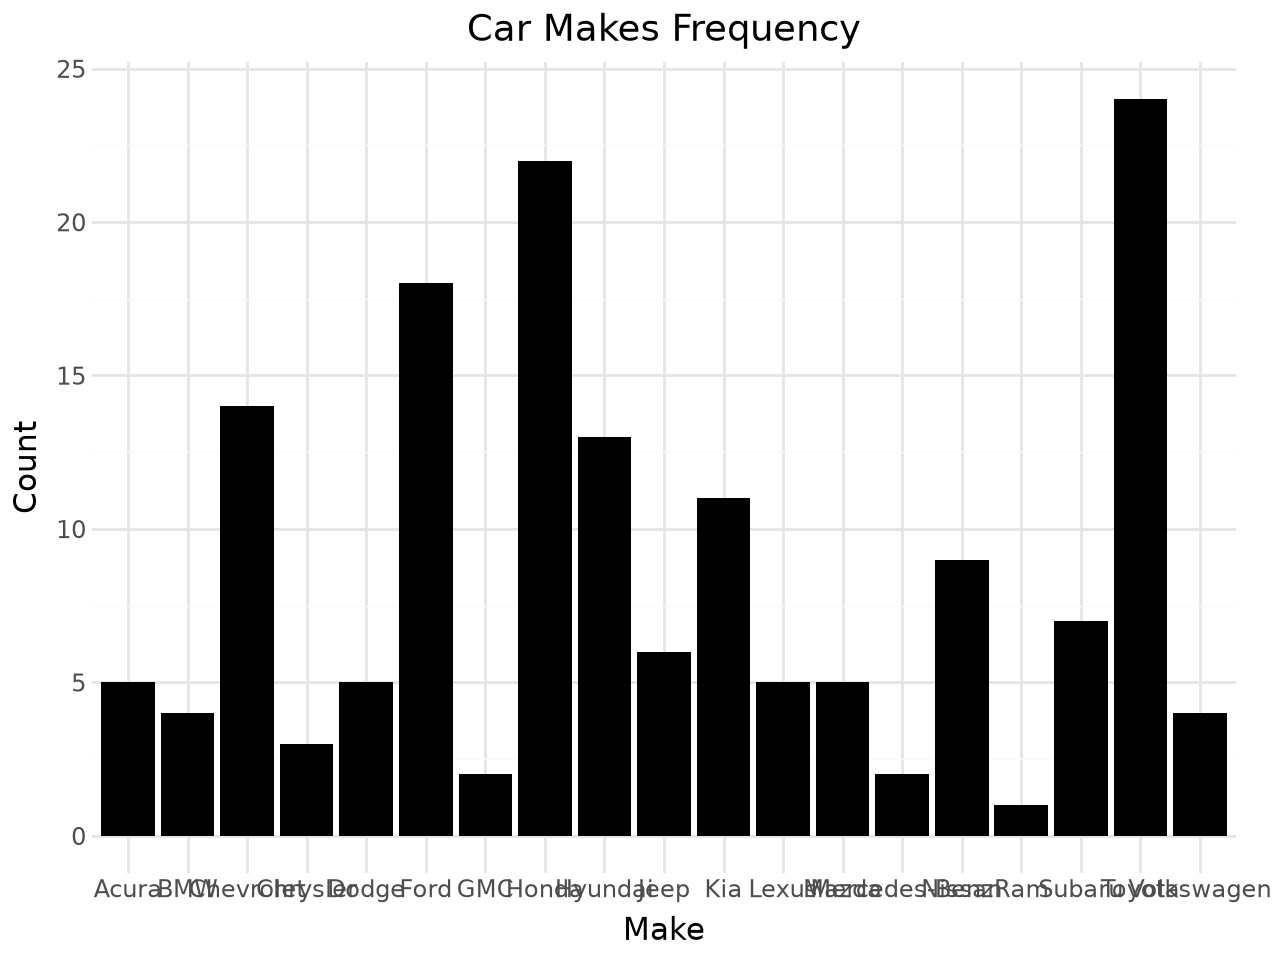

In [118]:
(
    ggplot(cars, aes(x="Make"))+ geom_bar(fill="black")
        + labs(
            title="Car Makes Frequency",
            x="Make",
            y="Count"
        )
    + theme_minimal()
)

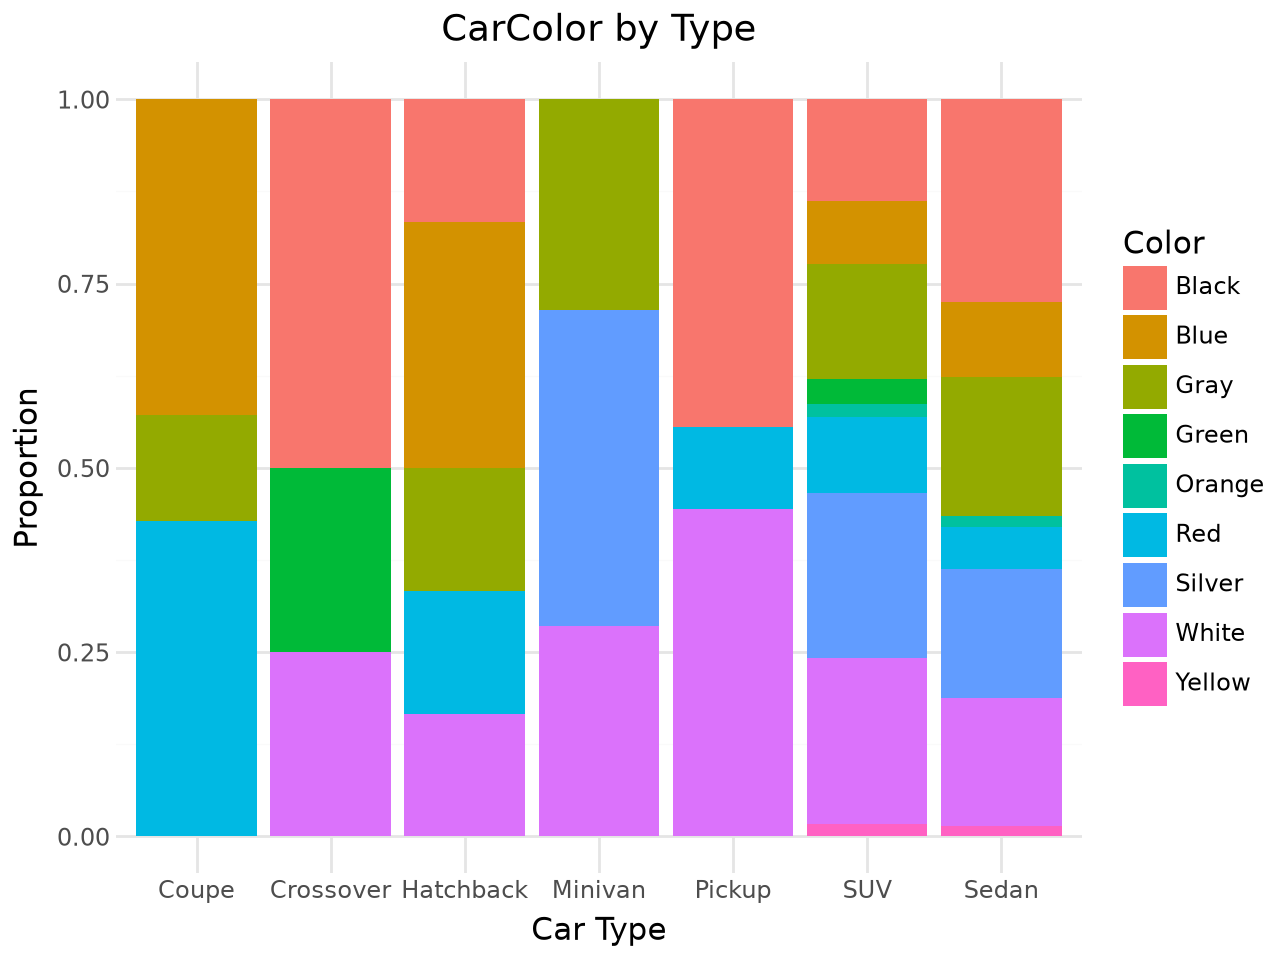

In [119]:
(
    ggplot(cars, aes(x="Type", fill="Color"))+ geom_bar(position="fill")
    + labs(
        title="CarColor by Type",
        x="Car Type",
        y="Proportion",
        fill="Color"
    )
    + theme_minimal()
)

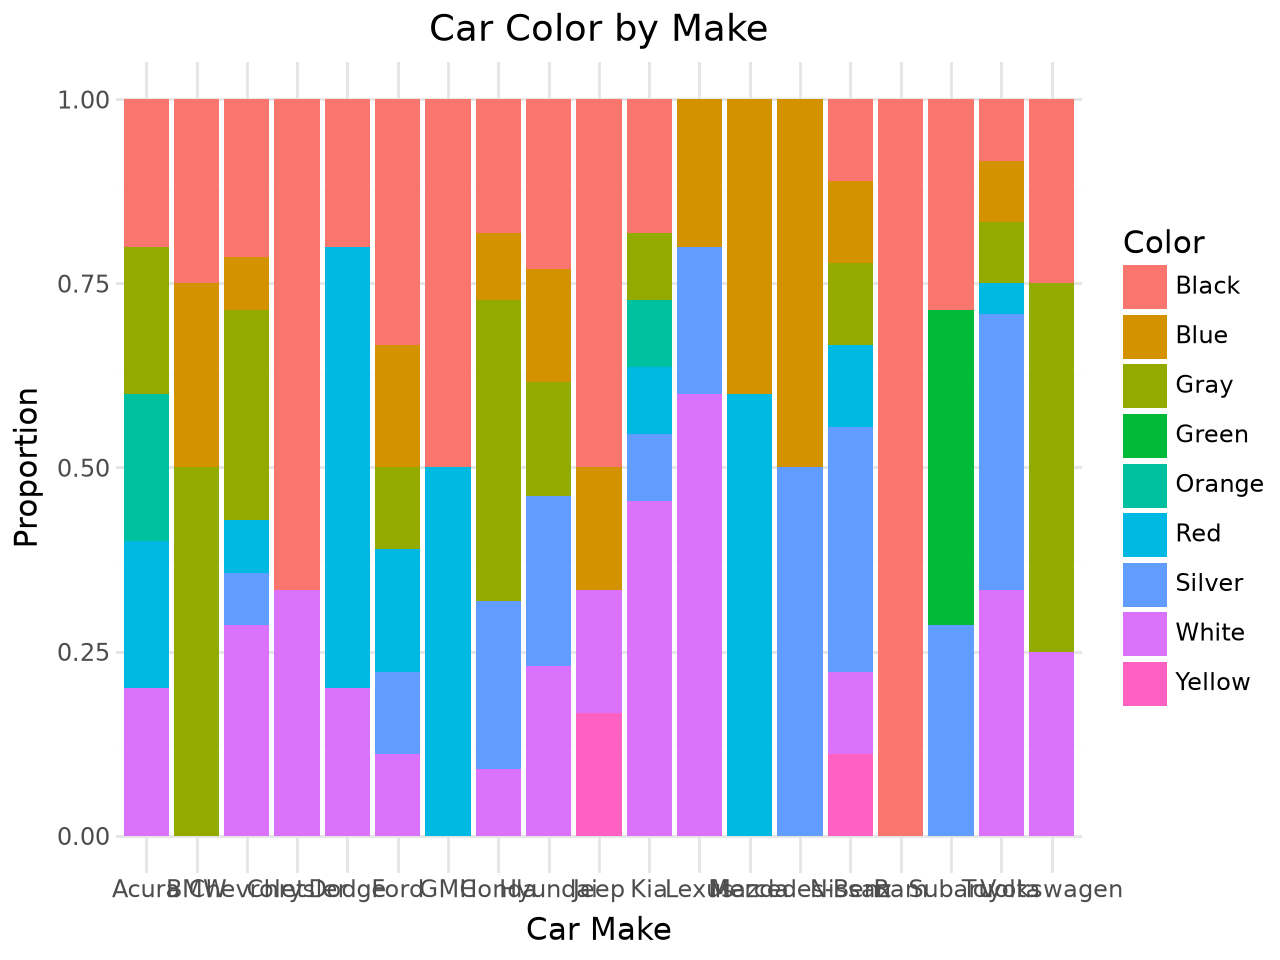

In [120]:
(
    ggplot(cars, aes(x="Make", fill="Color"))+ geom_bar(position="fill")
    + labs(
        title="Car Color by Make",
        x="Car Make",
        y="Proportion",
        fill="Color"
    )
    + theme_minimal()
)

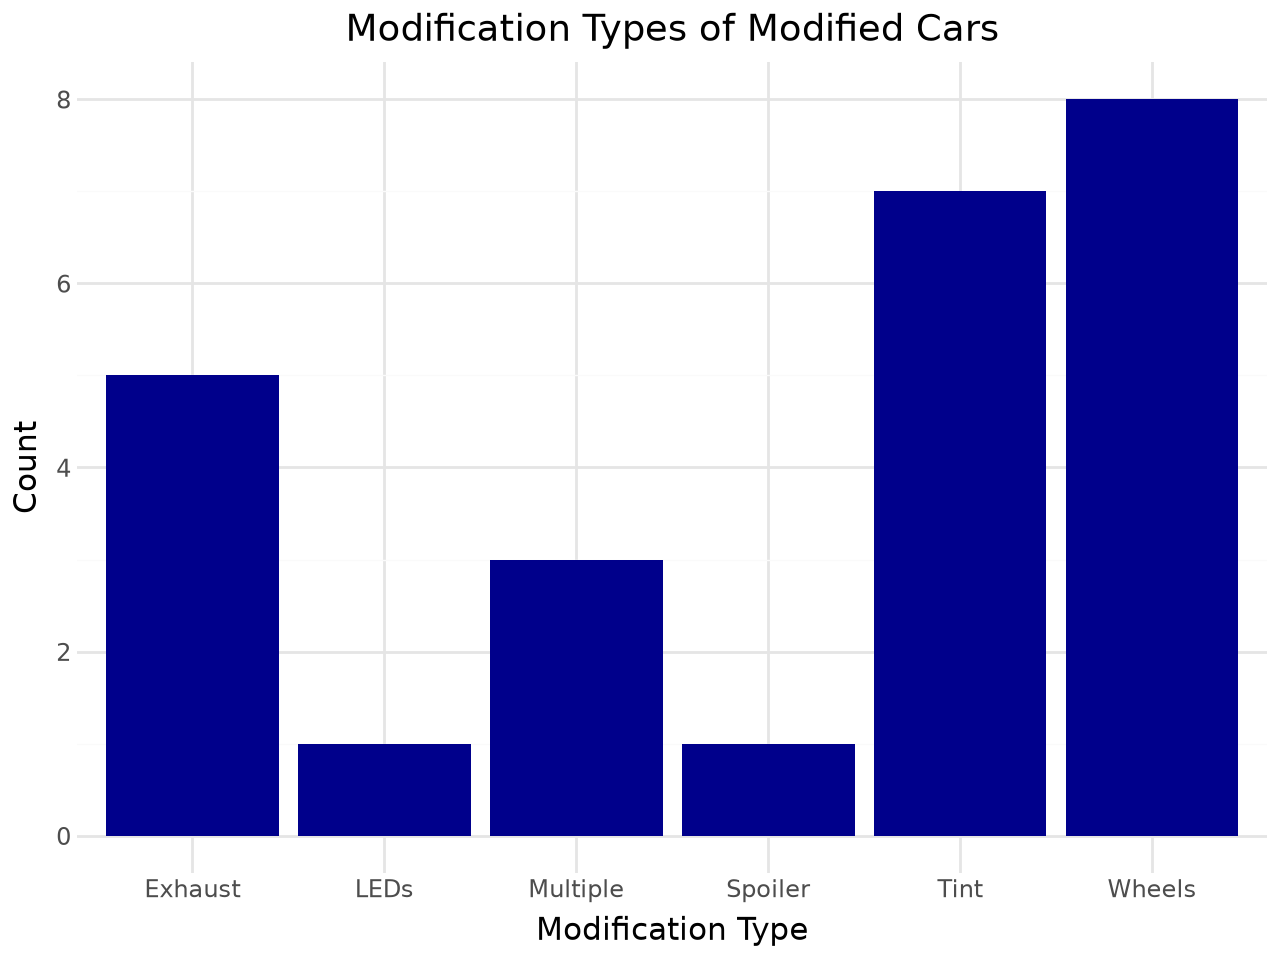

In [121]:
modifiedCars = cars[cars["Modified"] == "Yes"]

(
    ggplot(modifiedCars, aes(x="Mod_Type"))+ geom_bar(fill="darkblue")
    + labs(
        title="Modification Types of Modified Cars",
        x="Modification Type",
        y="Count"
    )
    + theme_minimal()
)

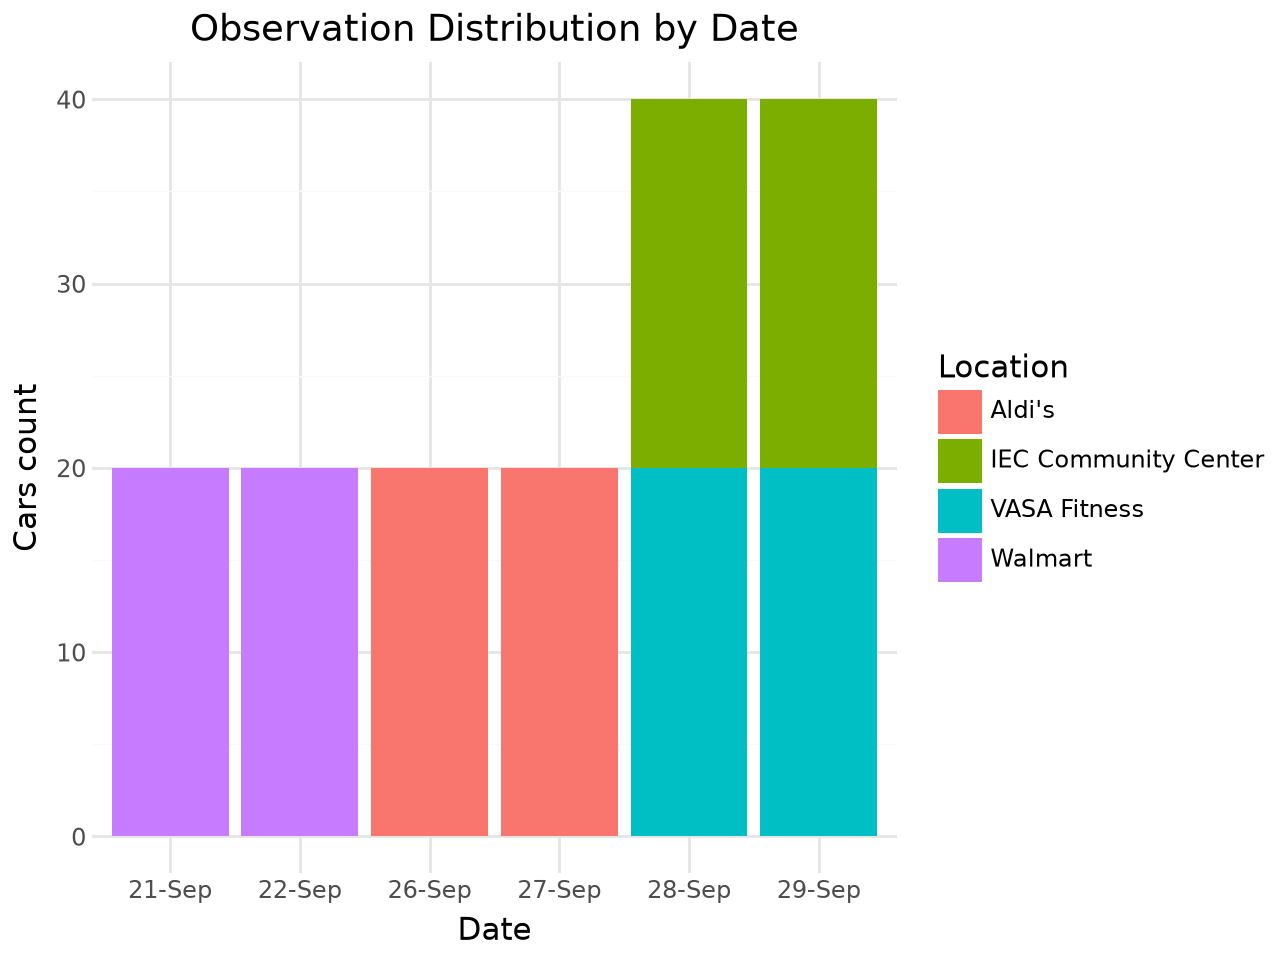

In [127]:
(
    ggplot(cars, aes(x="Date", fill="Location"))+ geom_bar()
    + labs(
        title="Observation Distribution by Date",
        x="Date",
        y="Cars count"
    )
    + theme_minimal()
)

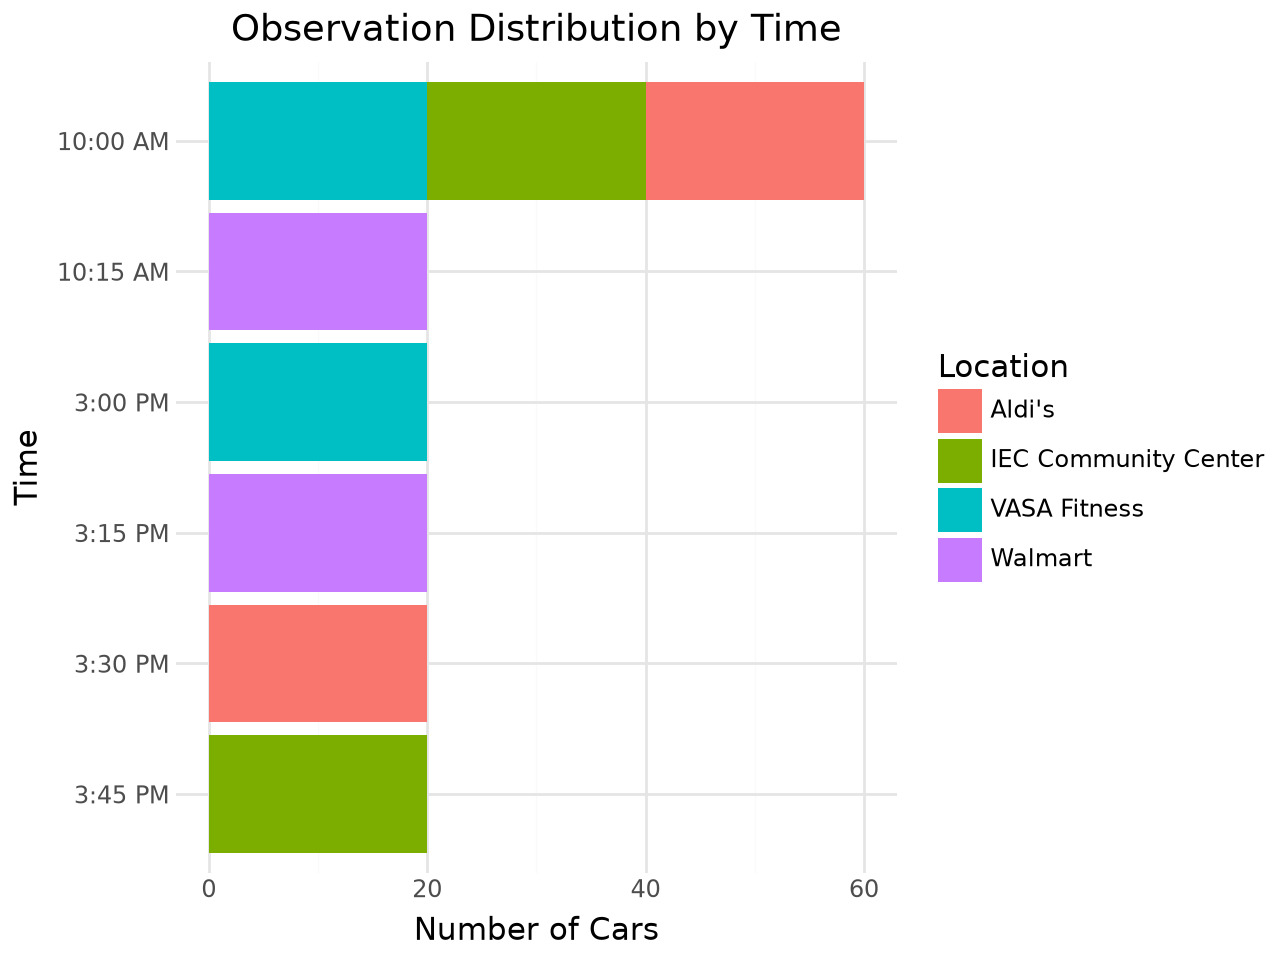

In [128]:
(
    ggplot(cars, aes(x="Time", fill="Location"))+ geom_bar()+ coord_flip() + scale_x_discrete(limits=['3:45 PM', '3:30 PM', '3:15 PM', '3:00 PM', '10:15 AM', '10:00 AM'])
    + labs(
        title="Observation Distribution by Time",
        x="Time",
        y="Number of Cars"
    )
    + theme_minimal()
)


Originallly I didn't have coord flip here, but I realized the common representation of times of day is typically done on the y axis.

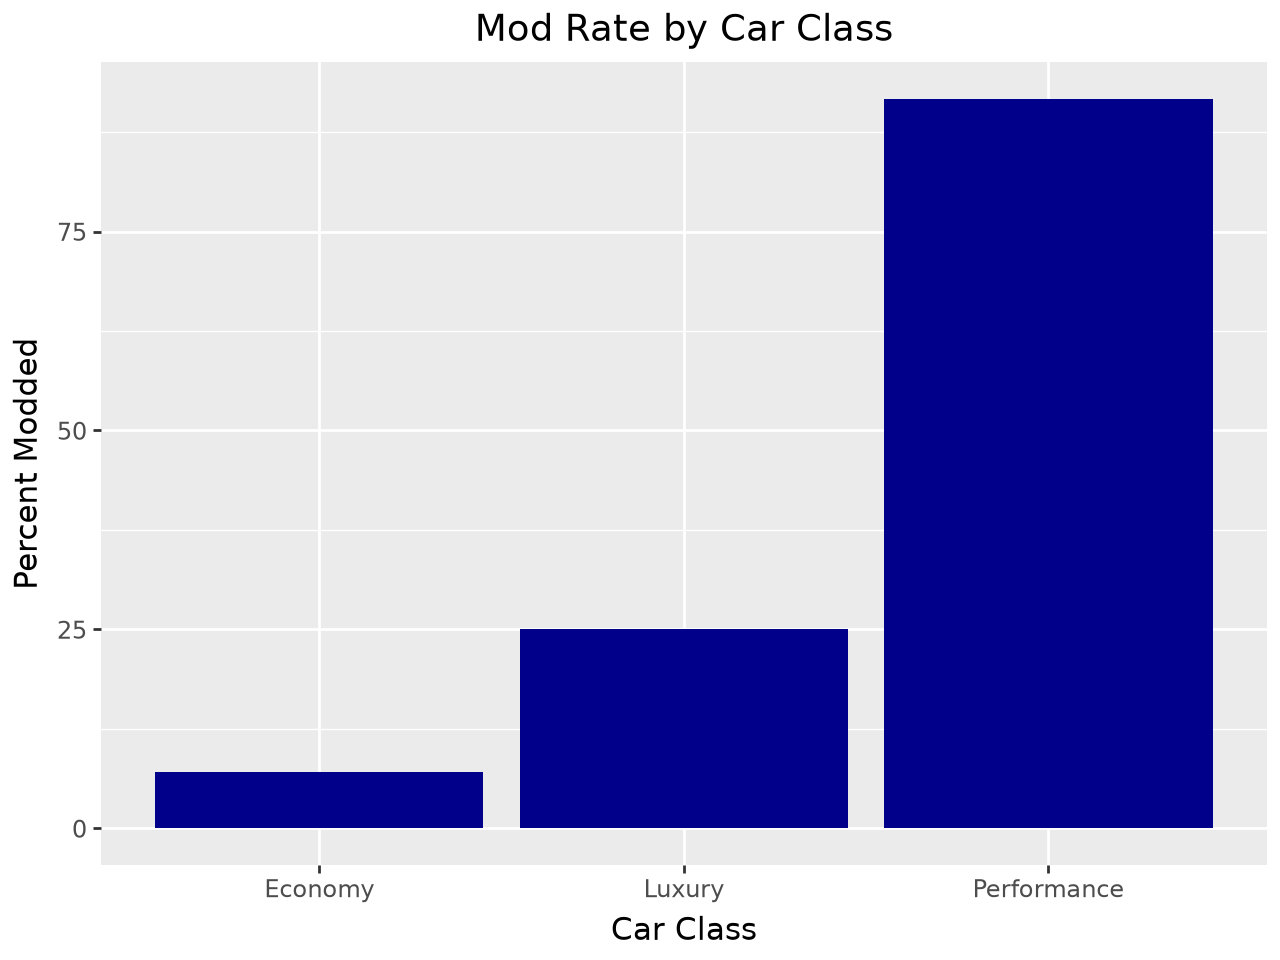

In [129]:
(
    ggplot(modRates, aes(x="Class", y="Percent Modified"))
    + geom_col(fill="darkblue")
    + labs(
        title="Mod Rate by Car Class",
        x="Car Class",
        y="Percent Modded",
    )
)

# Refined EDA
### Changes and the like are explained beneath the updated plots

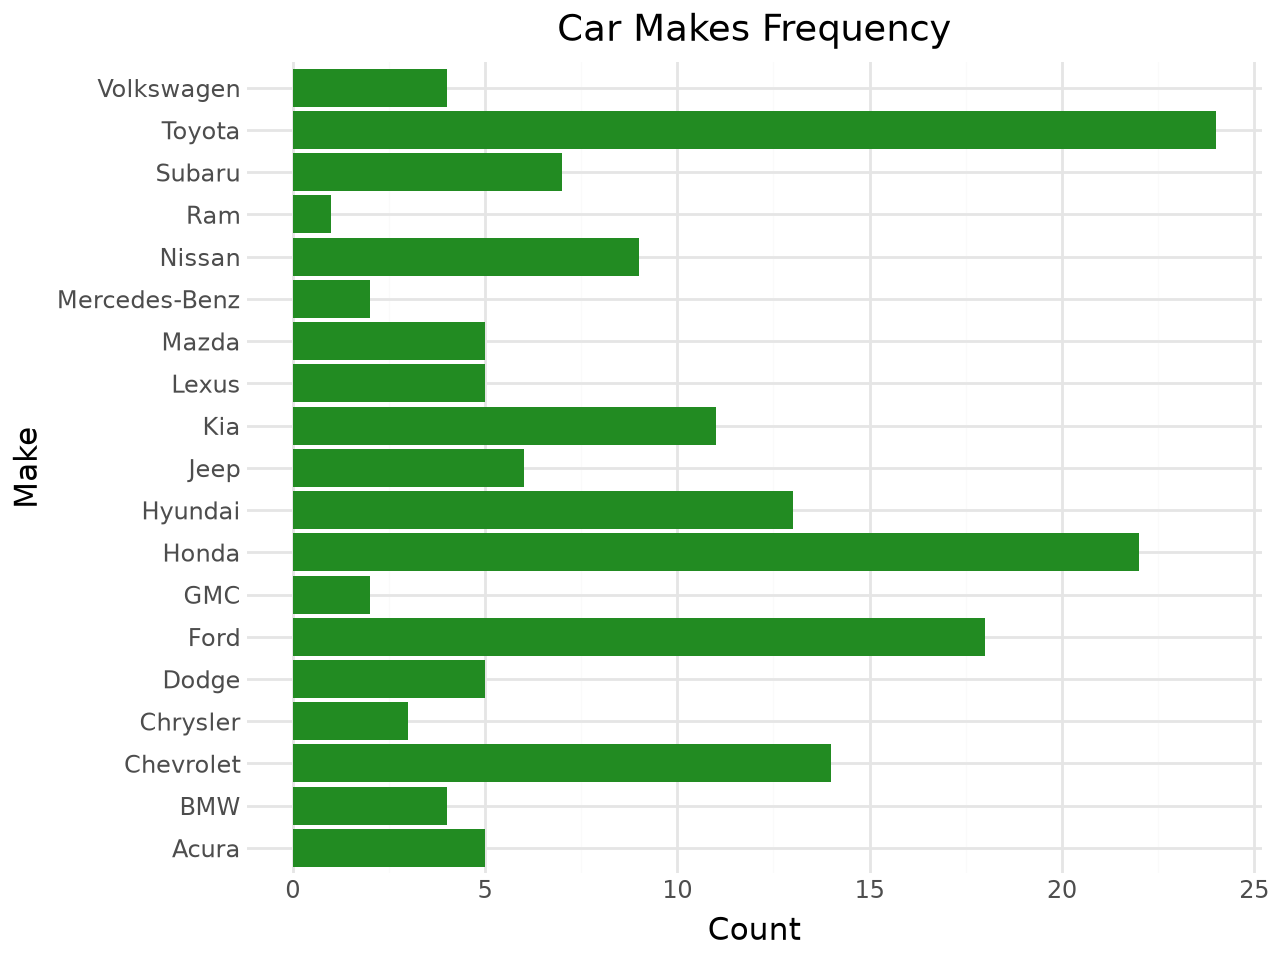

In [125]:
(
    ggplot(cars, aes(x="Make"))+ geom_bar(fill="forestgreen") + coord_flip()
        + labs(
            title="Car Makes Frequency",
            x="Make",
            y="Count"
        )
    + theme_minimal()
)

- Changes: Flipped X and Y because Make labels were overlapping, also changed color to be easier on the eyes

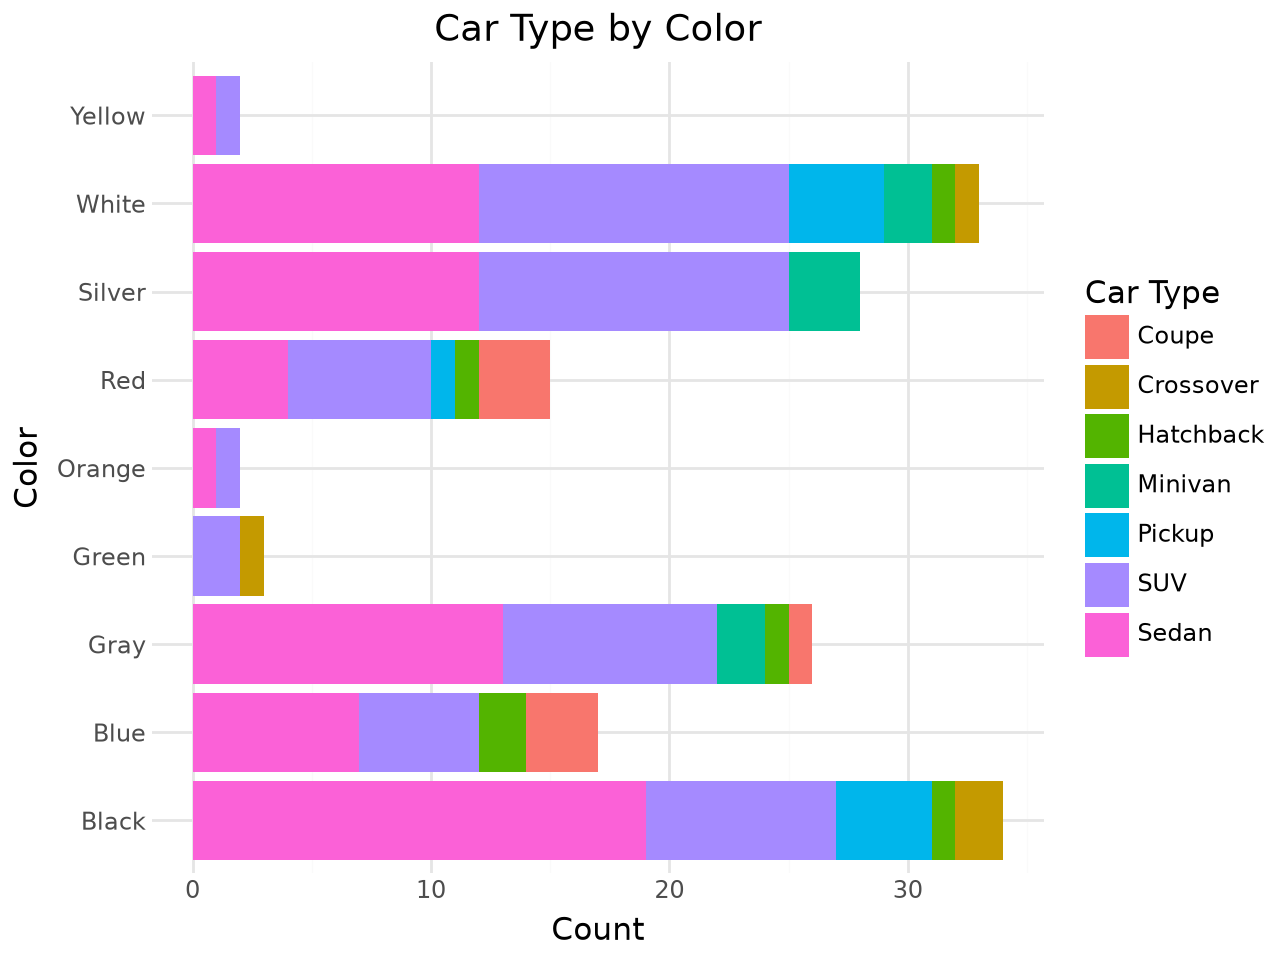

In [131]:
(
    ggplot(cars, aes(x="Color", fill="Type"))
    + geom_bar(position="stack")
    + coord_flip()
    + labs(
        title="Car Type by Color",
        x="Color",
        y="Count",
        fill="Car Type"
    )
    + theme_minimal()
)

- Changes: The original graph was colors by type. I realized while the graph looked cool, it had less accesible information than doing type by color. In type by color I can see both the most common and least common colors much easier than the first iteration, while still being able to understand the distribution of car types, for each color.

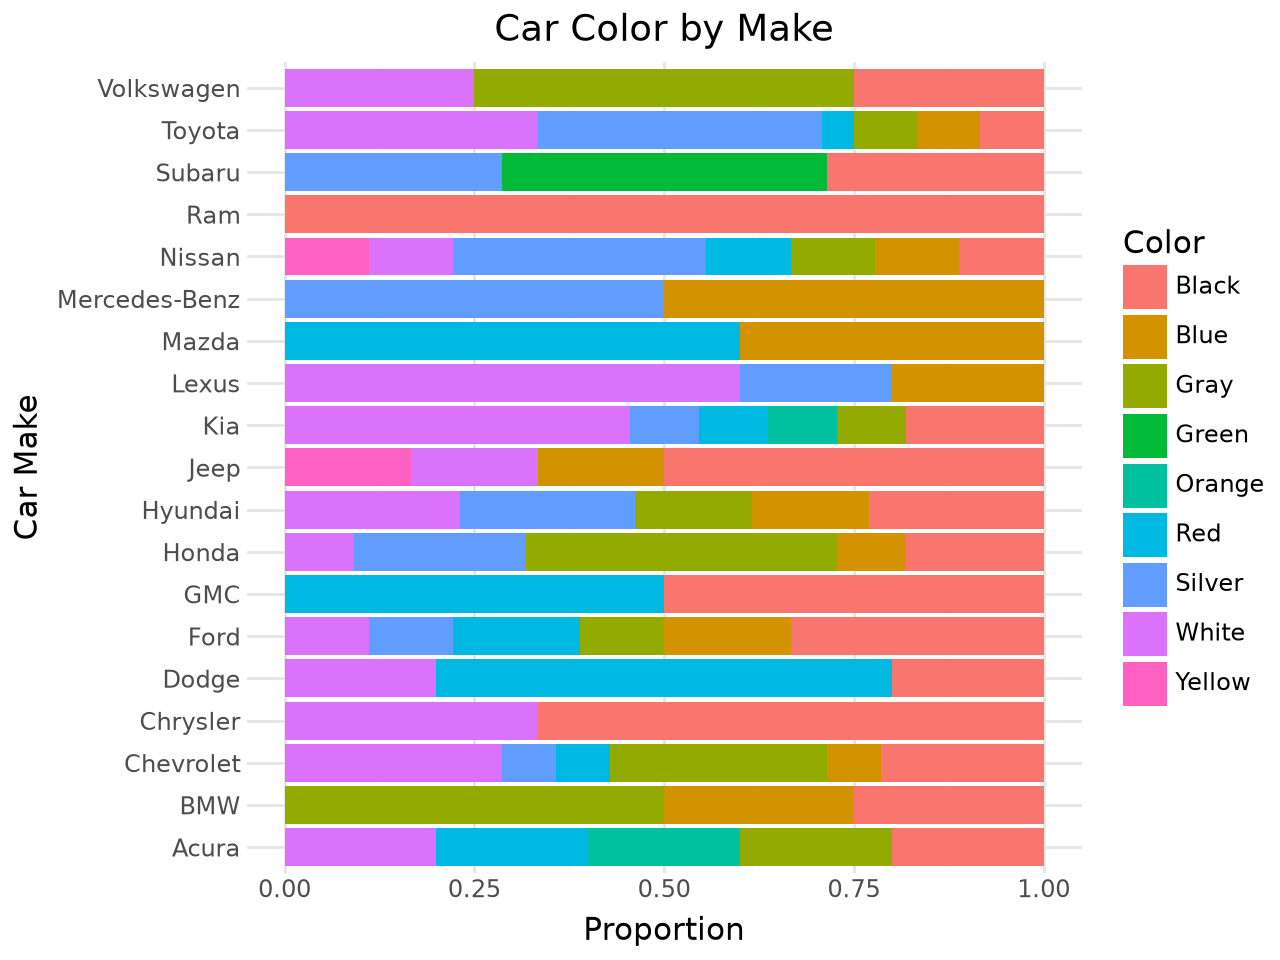

In [135]:
(
    ggplot(cars, aes(x="Make", fill="Color"))+ geom_bar(position="fill") +coord_flip()
    + labs(
        title="Car Color by Make",
        x="Car Make",
        y="Proportion",
        fill="Color"
    )
    + theme_minimal()
)

- Changes: Flipped X and Y axes for better visibility and easier comparisons between Manufacturers

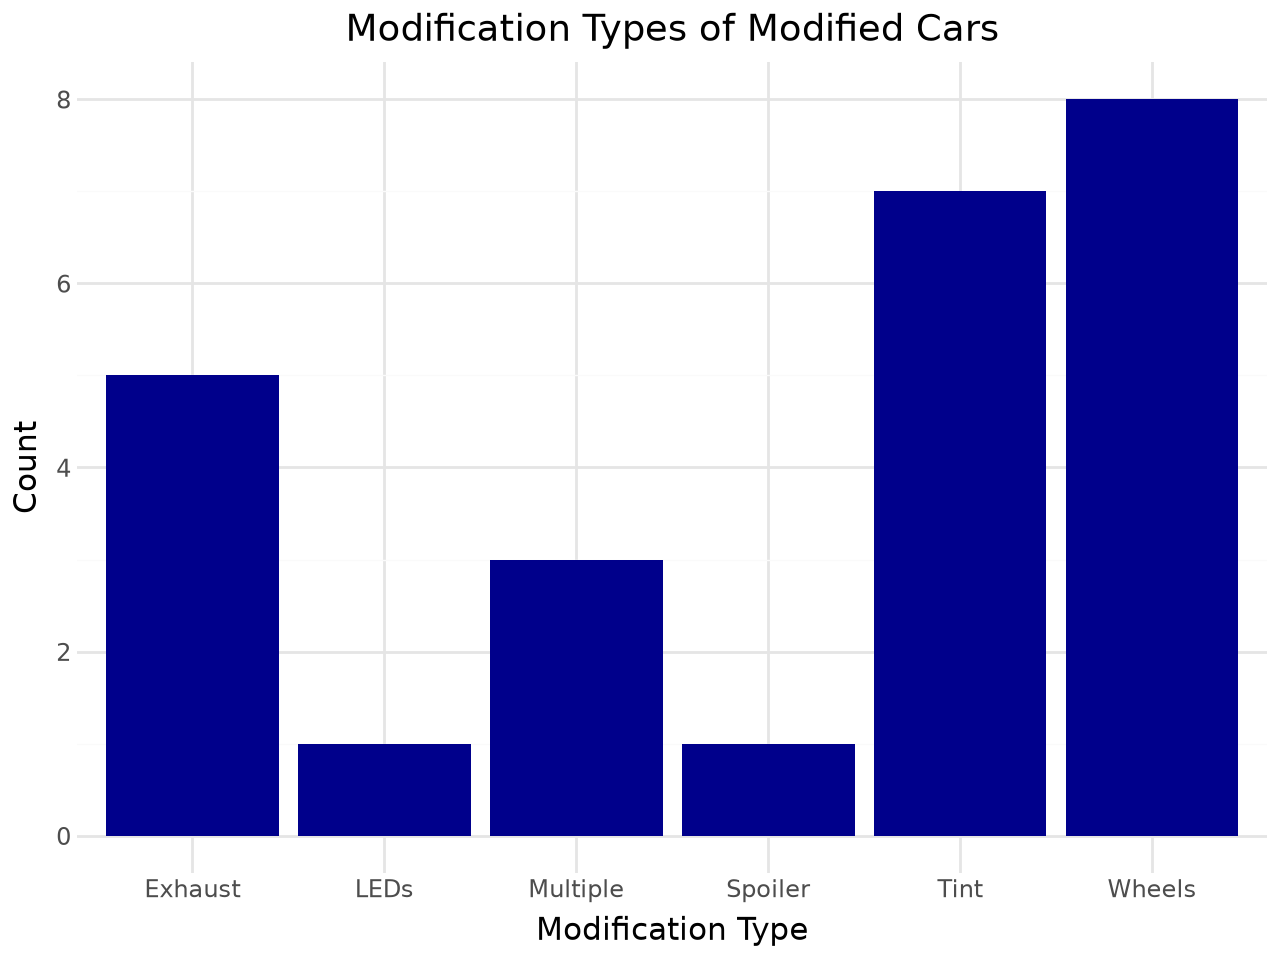

In [136]:
modifiedCars = cars[cars["Modified"] == "Yes"]

(
    ggplot(modifiedCars, aes(x="Mod_Type"))+ geom_bar(fill="darkblue")
    + labs(
        title="Modification Types of Modified Cars",
        x="Modification Type",
        y="Count"
    )
    + theme_minimal()
)

- No changes

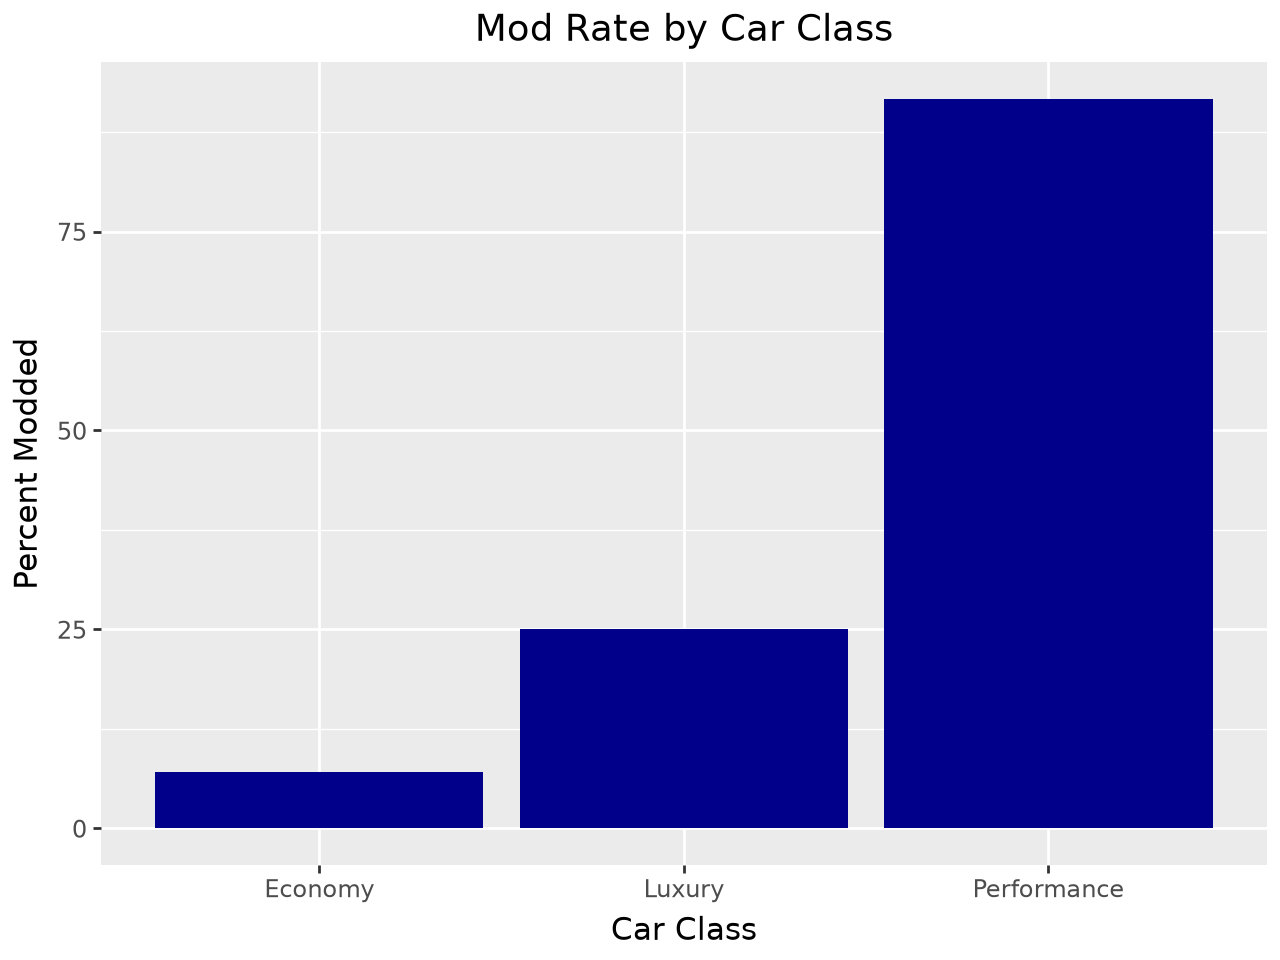

In [137]:
(
    ggplot(modRates, aes(x="Class", y="Percent Modified"))
    + geom_col(fill="darkblue")
    + labs(
        title="Mod Rate by Car Class",
        x="Car Class",
        y="Percent Modded",
    )
)

- No Changes

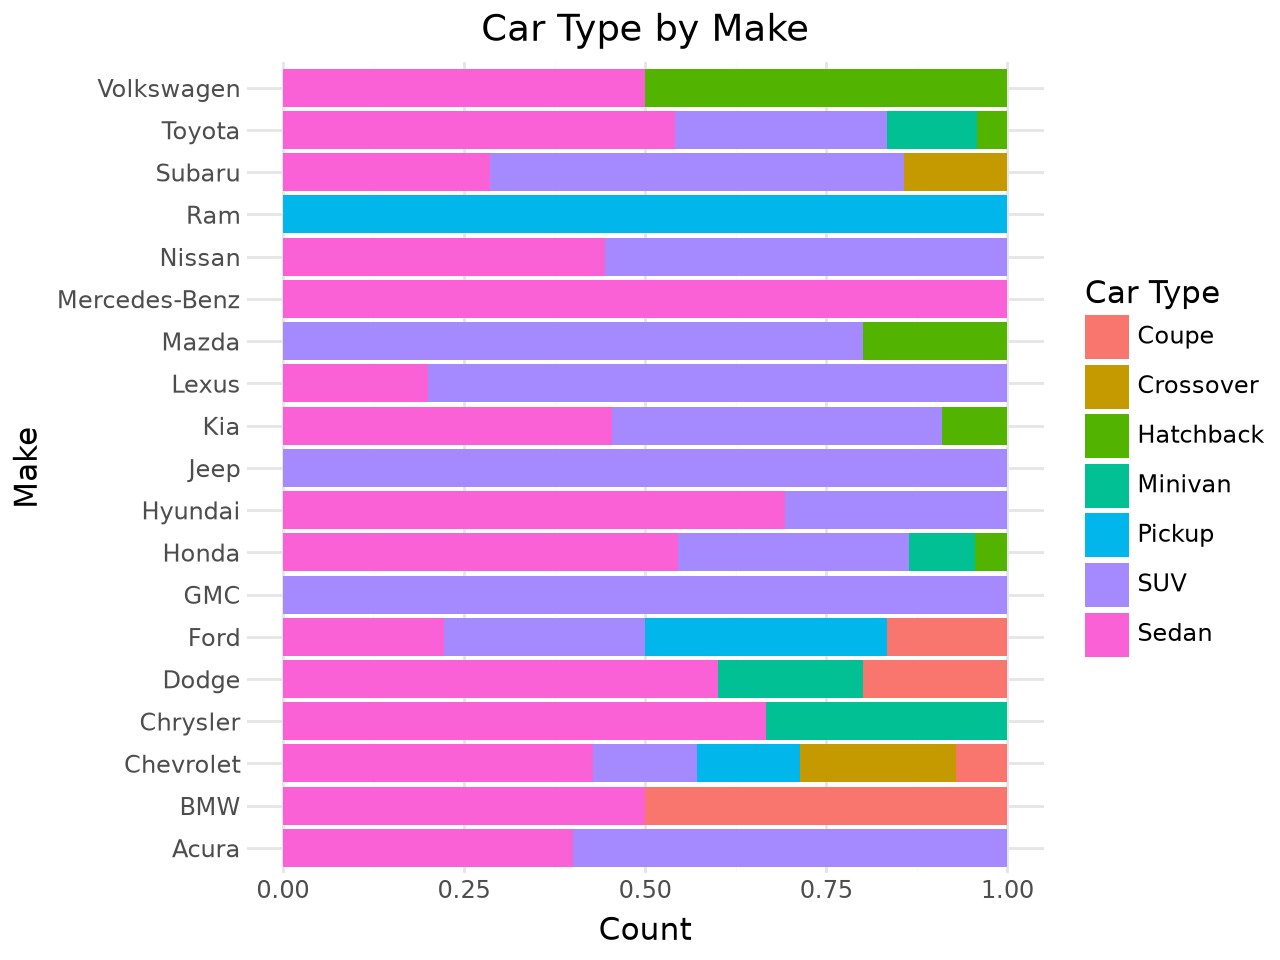

In [139]:
(
    ggplot(cars, aes(x="Make", fill="Type"))
    + geom_bar(position="fill")
    + coord_flip()
    + labs(
        title="Car Type by Make",
        x="Make",
        y="Count",
        fill="Car Type"
    )
    + theme_minimal()
)

- Changes: New chart! Shows type proportion by make.